# 03 · Análisis exploratorio de datos (EDA)

Se revisa primero el archivo en bruto (1990-2026) y luego la tabla procesada (2015-2026).

In [1]:
from pathlib import Path
import pandas as pd

# Carpeta del proyecto (funciona si el notebook se abre desde la raíz o desde notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'
OUT = ROOT / 'data' / 'processed'
FIG = ROOT / 'docs' / 'figures'
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
COLOR = {'basura': '#2a78d6', 'papel': '#eb6834', 'mgp': '#1baf7a'}
NOMBRE = {'basura': 'Basura común', 'papel': 'Papel', 'mgp': 'MGP'}

bruto = pd.read_csv(RAW / 'tonnage.csv')
bruto['month'] = pd.to_datetime(bruto['MONTH'].str.replace(' ', ''), format='%Y/%m')
df = pd.read_csv(OUT / 'residuos_mensuales.csv', parse_dates=['month'])
fracciones = ['basura', 'papel', 'mgp']

## 1. Estructura y tipos de variables

In [2]:
def estructura(tabla):
    return pd.DataFrame({'tipo': tabla.dtypes.astype(str),
                         'nulos_%': (tabla.isna().mean() * 100).round(1),
                         'valores_distintos': tabla.nunique()})

original = bruto.drop(columns='month')  # columnas tal como vienen en la fuente
print('En bruto:', original.shape)
estructura(original)

En bruto: (25355, 12)


,tipo,nulos_%,valores_distintos
MONTH,str,0.0,438
BOROUGH,str,0.0,5
COMMUNITYDISTRICT,int64,0.0,18
REFUSETONSCOLLECTED,float64,0.0,20206
PAPERTONSCOLLECTED,float64,9.6,8742
MGPTONSCOLLECTED,float64,8.2,7112
RESORGANICSTONS,float64,85.0,1849
SCHOOLORGANICTONS,float64,89.2,1093
LEAVESORGANICTONS,float64,96.5,693
XMASTREETONS,float64,93.4,568


In [3]:
print('Procesado:', df.shape)
estructura(df)

Procesado: (8319, 10)


,tipo,nulos_%,valores_distintos
month,datetime64[us],0.0,141
boro_cd,int64,0.0,59
BOROUGH,str,0.0,5
basura,float64,0.0,7667
papel,float64,0.0,4778
mgp,float64,0.0,4617
total,float64,0.0,7992
separacion_pct,float64,0.0,8319
nombre,str,0.0,59
poblacion_2010,int64,0.0,59


Hay variables temporales (`month`), categóricas (`BOROUGH`, `boro_cd`, `nombre`) y numéricas continuas (toneladas, porcentaje y población). Las columnas de orgánicos tienen entre 85 % y 97 % de vacíos porque esos programas empezaron tarde; por eso quedan fuera del estudio.

## 2. Faltantes, duplicados, inconsistencias y atípicos

In [4]:
# Vacíos de papel y MGP por año en el archivo en bruto
nulos = bruto.groupby(bruto['month'].dt.year)[['PAPERTONSCOLLECTED', 'MGPTONSCOLLECTED']].apply(lambda g: g.isna().sum())
nulos[nulos.sum(axis=1) > 0]

,PAPERTONSCOLLECTED,MGPTONSCOLLECTED
month,,
1990,89,89
1991,604,604
1992,708,708
1993,251,269
1994,11,12
1997,58,0
1998,107,0
1999,129,0
2000,174,0


In [5]:
print('Duplicados exactos:', bruto.duplicated().sum())
print('Distrito-mes repetidos:', bruto.duplicated(['BOROUGH_ID', 'COMMUNITYDISTRICT', 'month']).sum())
print('Registros de 1990 (año incompleto):', (bruto['month'].dt.year == 1990).sum())

Duplicados exactos:

 0
Distrito-mes repetidos: 0
Registros de 1990 (año incompleto): 89


Los vacíos se concentran entre 1990 y 2004, fuera del periodo de estudio. No hay duplicados.

Para los atípicos se usa la regla del rango intercuartílico (IQR): un valor es atípico si está 1,5 veces el IQR por debajo del primer cuartil o por encima del tercero.

In [6]:
def atipicos(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

pd.DataFrame({c: {'atipicos': atipicos(df[c]).sum(),
                  'distrito_mas_frecuente': df.loc[atipicos(df[c]), 'boro_cd'].mode()[0]}
              for c in fracciones + ['separacion_pct']}).T

,atipicos,distrito_mas_frecuente
basura,200,407
papel,277,108
mgp,188,412
separacion_pct,46,306


Los atípicos son pocos (menos del 4 %) y se repiten en los mismos distritos, como el 407 (Flushing), el 108 (Upper East Side) o el 412 (Jamaica), que recolectan mucho más que el resto; en separación, el atípico más repetido es el 306 (Park Slope), por arriba. Son valores reales de distritos grandes, no errores, así que **se conservan**.

## 3. Distribuciones, medidas descriptivas y tendencias

In [7]:
desc = df[fracciones + ['separacion_pct']].describe().T
desc['asimetria'] = df[fracciones + ['separacion_pct']].skew()
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,asimetria
basura,8319.0,4229.5,1612.9,1009.8,3067.4,4008.0,5152.3,10413.9,0.8
papel,8319.0,446.0,215.0,76.6,285.2,403.2,556.8,1516.0,1.2
mgp,8319.0,417.7,178.7,83.2,294.7,392.5,510.8,1254.6,0.8
separacion_pct,8319.0,17.4,5.4,3.2,13.6,17.1,20.8,35.4,0.3


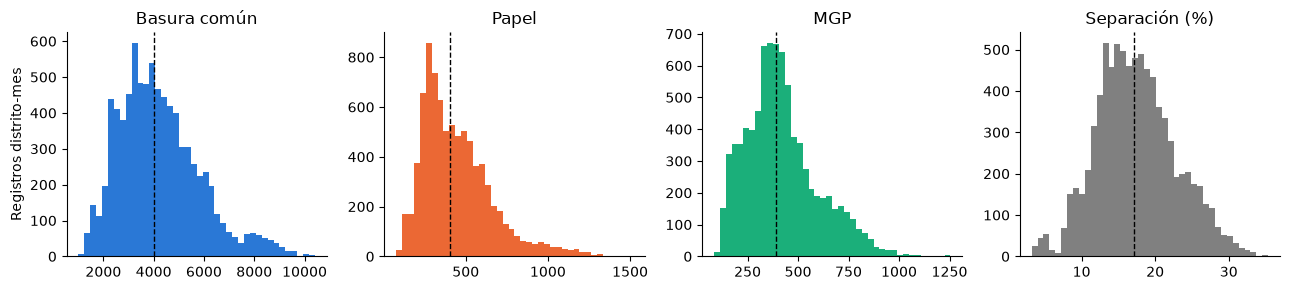

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, c in zip(axes, fracciones + ['separacion_pct']):
    ax.hist(df[c], bins=40, color=COLOR.get(c, 'gray'))
    ax.axvline(df[c].median(), color='black', ls='--', lw=1)
    ax.set_title(NOMBRE.get(c, 'Separación (%)'))
axes[0].set_ylabel('Registros distrito-mes')
plt.tight_layout()
plt.savefig(FIG / 'eda_distribuciones.png', dpi=150)
plt.show()

Las toneladas tienen asimetría positiva: la mayoría de distritos recolecta cantidades moderadas y unos pocos recolectan mucho. La línea punteada es la mediana, que aquí representa mejor el caso típico que la media.

**Tendencia anual** (se suman toneladas y luego se calcula el porcentaje):

In [9]:
anual = df.groupby(df['month'].dt.year)[fracciones].sum()
anual['meses'] = df.groupby(df['month'].dt.year)['month'].nunique()
anual['separacion_pct'] = 100 * (anual['papel'] + anual['mgp']) / anual[fracciones].sum(axis=1)
anual.round(1)

,basura,papel,mgp,meses,separacion_pct
month,,,,,
2015,2947235.8,318934.0,256594.3,12,16.3
2016,2965748.1,327347.3,281312.3,12,17.0
2017,2966507.3,319901.1,288829.0,12,17.0
2018,3023434.1,331556.6,295183.5,12,17.2
2019,2984427.5,323225.0,302838.4,12,17.3
2020,3122075.3,333159.4,352537.6,12,18.0
2021,3166924.8,334309.4,325118.0,12,17.2
2022,2992119.8,308674.5,296854.6,12,16.8
2023,2956231.6,296424.3,286541.4,12,16.5


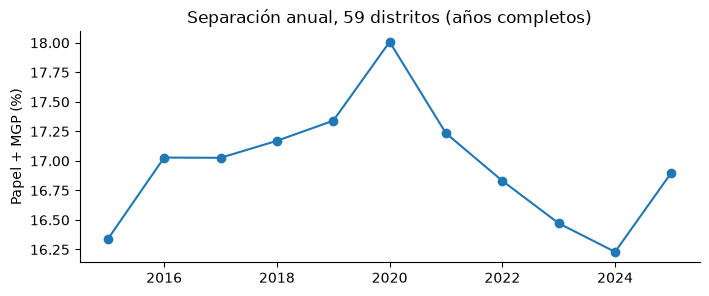

In [10]:
completos = anual[anual['meses'] == 12]
plt.figure(figsize=(8, 3))
plt.plot(completos.index, completos['separacion_pct'], marker='o')
plt.title('Separación anual, 59 distritos (años completos)')
plt.ylabel('Papel + MGP (%)')
plt.savefig(FIG / 'eda_tendencia_anual.png', dpi=150, bbox_inches='tight')
plt.show()

**Estacionalidad** (promedio por mes del año):

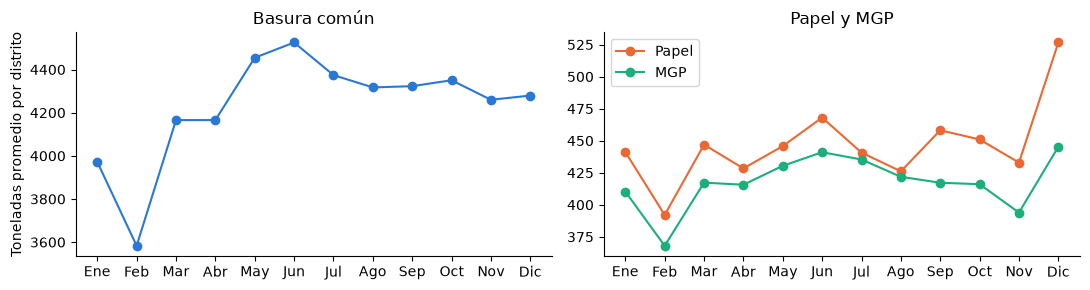

In [11]:
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
estacional = df.groupby(df['month'].dt.month)[fracciones].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(meses, estacional['basura'], marker='o', color=COLOR['basura'])
axes[0].set_title('Basura común')
for c in ['papel', 'mgp']:
    axes[1].plot(meses, estacional[c], marker='o', color=COLOR[c], label=NOMBRE[c])
axes[1].set_title('Papel y MGP')
axes[1].legend()
axes[0].set_ylabel('Toneladas promedio por distrito')
plt.tight_layout()
plt.savefig(FIG / 'eda_estacionalidad.png', dpi=150)
plt.show()

## 4. Relaciones, segmentaciones y correlaciones

**Por borough:**

In [12]:
boro = df.groupby('BOROUGH')[fracciones].sum()
boro['separacion_pct'] = 100 * (boro['papel'] + boro['mgp']) / boro.sum(axis=1)
boro.sort_values('separacion_pct').round(1)

,basura,papel,mgp,separacion_pct
BOROUGH,,,,
Bronx,6246996.0,438700.0,530751.2,13.4
Brooklyn,11348272.0,1114116.4,979070.9,15.6
Queens,8969858.0,973733.2,1060070.6,18.5
Staten Island,2367562.3,280727.6,268221.8,18.8
Manhattan,6252441.7,902845.4,636441.8,19.8


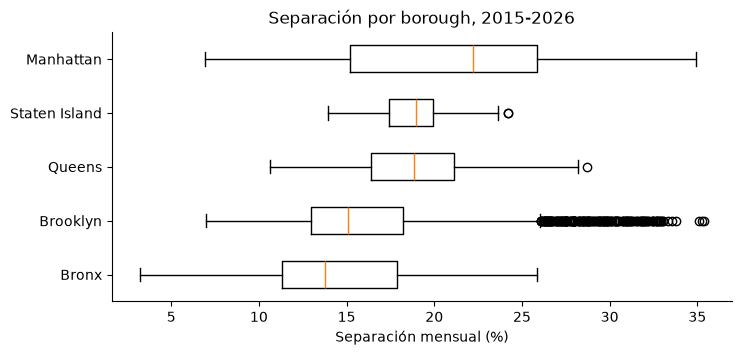

In [13]:
orden = boro.sort_values('separacion_pct').index
plt.figure(figsize=(8, 3.5))
plt.boxplot([df.loc[df['BOROUGH'] == b, 'separacion_pct'] for b in orden], orientation='horizontal', tick_labels=orden)
plt.xlabel('Separación mensual (%)')
plt.title('Separación por borough, 2015-2026')
plt.savefig(FIG / 'eda_borough.png', dpi=150, bbox_inches='tight')
plt.show()

**Correlaciones** (Spearman, porque las variables no son normales):

In [14]:
corr = df[fracciones + ['separacion_pct', 'poblacion_2010']].corr(method='spearman')
corr.round(2)

,basura,papel,mgp,separacion_pct,poblacion_2010
basura,1.00,0.43,0.58,-0.33,0.68
papel,0.43,1.00,0.75,0.60,0.56
mgp,0.58,0.75,1.00,0.43,0.77
separacion_pct,-0.33,0.60,0.43,1.00,0.06
poblacion_2010,0.68,0.56,0.77,0.06,1.00


**Por distrito** (todo el periodo):

In [15]:
dist = df.groupby(['boro_cd', 'nombre'])[fracciones].sum()
dist['separacion_pct'] = 100 * (dist['papel'] + dist['mgp']) / dist.sum(axis=1)
print('Menor separación:')
display(dist.sort_values('separacion_pct').head(5).round(1))
print('Mayor separación:')
display(dist.sort_values('separacion_pct').tail(5).round(1))

Menor separación:


,,basura,papel,mgp,separacion_pct
boro_cd,nombre,,,,
202,"Hunts Point, Longwood",1156938.0,28812.8,29654.9,4.8
110,Central Harlem,878716.8,40426.6,38183.7,8.2
316,"Brownsville, Ocean Hill",422719.2,20247.0,22325.3,9.1
308,Crown Heights North,833844.7,44742.3,39906.8,9.2
201,"Melrose, Mott Haven, Port Morris",453366.7,33939.5,19838.1,10.6


Mayor separación:


,,basura,papel,mgp,separacion_pct
boro_cd,nombre,,,,
302,"Brooklyn Heights, Fort Greene",373929.6,73756.4,54519.6,25.5
106,"Stuyvesant Town, Turtle Bay",456319.4,110164.7,55366.4,26.6
107,"West Side, Upper West Side",675612.7,147812.8,102227.1,27.0
101,"Battery Park City, Tribeca",214762.0,51683.1,34083.7,28.5
306,"Park Slope, Carroll Gardens",316696.8,78728.7,56776.0,30.0


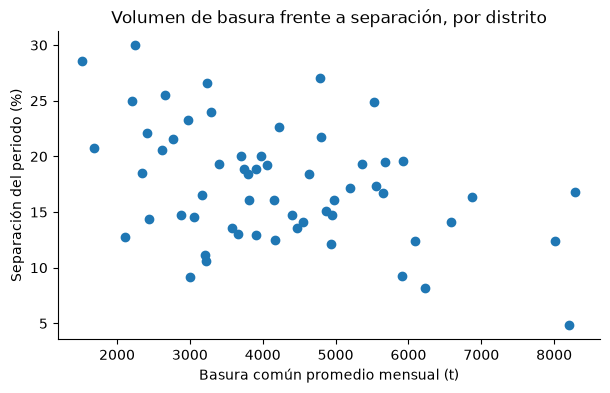

In [16]:
plt.figure(figsize=(7, 4))
plt.scatter(dist['basura'] / 141, dist['separacion_pct'])
plt.xlabel('Basura común promedio mensual (t)')
plt.ylabel('Separación del periodo (%)')
plt.title('Volumen de basura frente a separación, por distrito')
plt.savefig(FIG / 'eda_relaciones.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Visualizaciones de datos en bruto
Serie completa del archivo original (1990-2026), sin filtrar ni limpiar. La franja azul marca el periodo de estudio.

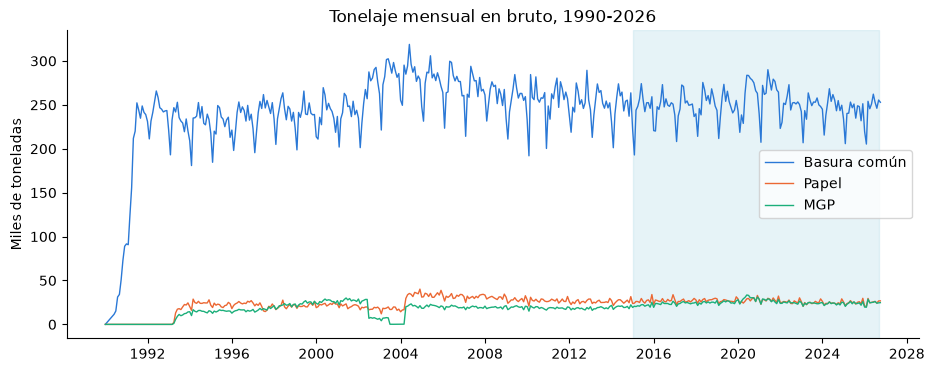

In [17]:
serie = bruto.groupby('month')[['REFUSETONSCOLLECTED', 'PAPERTONSCOLLECTED', 'MGPTONSCOLLECTED']].sum() / 1000
serie.columns = fracciones

plt.figure(figsize=(11, 4))
for c in fracciones:
    plt.plot(serie.index, serie[c], color=COLOR[c], label=NOMBRE[c], lw=1)
plt.axvspan(pd.Timestamp('2015-01-01'), pd.Timestamp('2026-09-01'), color='lightblue', alpha=0.3)
plt.ylabel('Miles de toneladas')
plt.title('Tonelaje mensual en bruto, 1990-2026')
plt.legend()
plt.savefig(FIG / 'eda_serie_bruta.png', dpi=150, bbox_inches='tight')
plt.show()

Las caídas de papel y MGP antes de 2005 coinciden con los años con vacíos en la fuente; en ese tiempo la ciudad también suspendió parte del reciclaje de vidrio y plástico (2002-2004). Esto confirma la decisión de empezar en 2015.

## 6. Hallazgos preliminares y decisiones

| Hallazgo | Decisión |
|---|---|
| Vacíos de papel y MGP entre 1990 y 2004 | Usar 2015-2026, periodo completo |
| Orgánicos con 85-97 % de vacíos | Dejarlos fuera del indicador |
| Sin duplicados, nulos ni negativos en 2015-2026 | No imputar ni eliminar registros |
| Atípicos en distritos grandes (407, 108, 412) | Conservarlos: son valores reales |
| Toneladas con asimetría positiva | Usar mediana y cuartiles para comparar |
| Separación estable (~16-18 %) con pico en 2020 | Revisar el efecto de la pandemia antes de concluir |
| Bronx y Brooklyn con menor separación | Priorizarlos en el mapa y el tablero |
| Correlación negativa entre basura y separación (-0,33) | Comparar distritos con el porcentaje, no con toneladas absolutas |